# MobileNetV2 en Colab — PlantVillage (autocontenido)

Notebook autocontenido para Google Colab: todo el código vive en las celdas; la única descarga externa es el dataset PlantVillage. No importa del paquete `leafthealthvision` ni de archivos locales del proyecto.

Ruta F: comparación con EfficientNetB0 bajo mismas particiones, resolución, preprocesamiento y métricas.

> **Advertencia:** resultado orientativo, no diagnóstico agrícola. No declara cumplimiento completo del proyecto ni generalización a campo.


In [96]:
# 0. Instalar dependencias (solo librerías externas; el código del proyecto va en las celdas)
!pip -q install tensorflow==2.21.0 mlflow==3.18.0 codecarbon>=3.3.2 scikit-learn==1.7.2 matplotlib==3.10.9


In [97]:
# 1. Descargar el dataset real de PlantVillage (única descarga externa de datos)
import shutil
import subprocess
from pathlib import Path

WORK = Path("/content/leafthealthvision")
DATA_DIR = WORK / "data" / "plantvillage"
REPO_URL = "https://github.com/spMohanty/PlantVillage-Dataset.git"

if not DATA_DIR.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    print(f"Clonando {REPO_URL} ...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(DATA_DIR)], check=True)
    git_dir = DATA_DIR / ".git"
    if git_dir.exists():
        shutil.rmtree(git_dir)
    for item in DATA_DIR.iterdir():
        if item.name not in {"raw", "leaf_grouping", "leaf-map.json", "README.md", "CITATION.cff"}:
            if item.is_dir():
                shutil.rmtree(item)
            else:
                item.unlink()
    print("Dataset listo en:", DATA_DIR)
else:
    print("Dataset ya descargado en:", DATA_DIR)

data_dir = DATA_DIR / "raw" / "color"
print("Imágenes en:", data_dir)
print("Clases encontradas:", len([p for p in data_dir.iterdir() if p.is_dir()]))


Dataset ya descargado en: /content/leafthealthvision/data/plantvillage
Imágenes en: /content/leafthealthvision/data/plantvillage/raw/color
Clases encontradas: 38


In [98]:
# 2. Configuración (equivalente a src/leafthealthvision/config/settings.py)
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import applications, layers
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        print(f"GPU activada: {len(gpus)} dispositivo(s), mixed_float16")
    except RuntimeError as e:
        print(f"Nota GPU (ya inicializada): {e}")
else:
    print("No se detectó GPU; se usará CPU")

SEED = 42
BATCH_SIZE = 640
IMAGE_TARGET_SIZE = (224, 224)
OPTIMIZER = "adam"
METRICS = ["accuracy"]
EARLY_STOPPING_PATIENCE = 5
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.1
TEST_SPLIT = 0.1
EPOCHS = 10

CLASS_NAMES = [
    "Apple___Apple_scab", "Apple___Black_rot", "Apple___Cedar_apple_rust", "Apple___healthy",
    "Blueberry___healthy", "Cherry_(including_sour)___Powdery_mildew", "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot", "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight", "Corn_(maize)___healthy",
    "Grape___Black_rot", "Grape___Esca_(Black_Measles)", "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)", "Grape___healthy",
    "Orange___Haunglongbing_(Citrus_greening)", "Peach___Bacterial_spot", "Peach___healthy",
    "Pepper,_bell___Bacterial_spot", "Pepper,_bell___healthy",
    "Potato___Early_blight", "Potato___Late_blight", "Potato___healthy",
    "Raspberry___healthy", "Soybean___healthy", "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch", "Strawberry___healthy",
    "Tomato___Bacterial_spot", "Tomato___Early_blight", "Tomato___Late_blight",
    "Tomato___Leaf_Mold", "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite", "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus", "Tomato___Tomato_mosaic_virus", "Tomato___healthy",
]
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {n: i for i, n in enumerate(CLASS_NAMES)}

tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("Clases:", NUM_CLASSES, "| Imagen objetivo:", IMAGE_TARGET_SIZE, "| Batch:", BATCH_SIZE)


GPU activada: 1 dispositivo(s), mixed_float16
Clases: 38 | Imagen objetivo: (224, 224) | Batch: 640


In [99]:
# 3. MLflow: seguimiento del experimento (se guarda en ./mlruns del entorno)

import mlflow
import mlflow.tensorflow
from codecarbon import EmissionsTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("leafthealthvision")

class MlflowEpochLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        mlflow.log_metrics({k: float(v) for k, v in logs.items()}, step=epoch)


## 4. Cargar dataset desde manifiestos (determinista, sin fuga entre splits)

Se generan manifiestos `train/val/test` a partir de `raw/color` con semilla 42, agrupando por hash SHA-256 para evitar duplicados entre splits. Cada imagen queda en un solo split y las 38 clases aparecen en train/val/test.


In [100]:
import csv
import hashlib
import random
from collections import Counter, defaultdict

random.seed(SEED)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()

def leaf_name(nombre):
    stem = Path(nombre).stem
    stem = stem.removesuffix("_final_masked")
    partes = stem.split("___")
    if len(partes) >= 2:
        return f"{partes[0]}___{partes[1]}"
    return stem

# hash -> lista de (categoria, nombre)
hash_a_items = defaultdict(list)
total = 0
for clase_dir in sorted(data_dir.iterdir()):
    if not clase_dir.is_dir():
        continue
    categoria = clase_dir.name
    for img in sorted(clase_dir.iterdir()):
        if img.suffix.lower() in (".jpg", ".jpeg", ".png"):
            h = sha256_file(img)
            hash_a_items[h].append((categoria, img.name))
            total += 1

items_unicos = []
conflictos = []
for h, items in hash_a_items.items():
    cats = Counter(c for c, _ in items)
    categoria_elegida = cats.most_common(1)[0][0]
    if len(cats) > 1:
        conflictos.append((h, dict(cats), categoria_elegida))
    items_unicos.append((h, categoria_elegida, items[0][1]))

random.shuffle(items_unicos)
n = len(items_unicos)
n_train = max(1, round(n * TRAIN_SPLIT))
n_val = max(1, round(n * VAL_SPLIT))
n_test = n - n_train - n_val
if n_test < 1:
    n_train = max(1, n - 2)
    n_val = 1
    n_test = 1

grupos = {
    "train": items_unicos[:n_train],
    "val": items_unicos[n_train:n_train + n_val],
    "test": items_unicos[n_train + n_val:],
}

splits_rows = {"train": [], "val": [], "test": []}
for split, items in grupos.items():
    for h, categoria, _ in items:
        for categoria_arch, nombre_arch in hash_a_items[h]:
            splits_rows[split].append({
                "archivo": nombre_arch,
                "categoria": categoria,
                "split": split,
                "hash": h,
                "hoja": leaf_name(nombre_arch),
            })

# Verificación: ningún hash en más de un split
hash_a_split = {}
for split in ("train", "val", "test"):
    for r in splits_rows[split]:
        h = r["hash"]
        assert h not in hash_a_split or hash_a_split[h] == split, f"hash compartido: {h}"
        hash_a_split[h] = split

clases = sorted({c for items in hash_a_items.values() for c, _ in items})
assert set(clases) == set(CLASS_NAMES), "Clases del manifiesto no coinciden con CLASS_NAMES"

for split in ("train", "val", "test"):
    cats = {r["categoria"] for r in splits_rows[split]}
    assert cats == set(CLASS_NAMES), f"{split} no tiene las {NUM_CLASSES} clases"

print(f"Archivos totales: {total} | Únicas: {len(items_unicos)} | Clases: {len(clases)}")
print(f"train: {len(splits_rows['train'])} | val: {len(splits_rows['val'])} | test: {len(splits_rows['test'])}")
print(f"Conflictos de etiquetado documentados: {len(conflictos)}")


Archivos totales: 54305 | Únicas: 54284 | Clases: 38
train: 43442 | val: 5430 | test: 5433
Conflictos de etiquetado documentados: 0


## 5. tf.data desde manifiestos y pesos de clase (solo train)

Se construyen `tf.data.Dataset` leyendo imágenes desde disco según los manifiestos. Los pesos de clase se calculan **exclusivamente con train** (`N / (K · n_clase)`). Las imágenes se entregan en `[0,255]`; el preprocesamiento a `[-1,1]` va dentro del modelo.


In [101]:
from tensorflow.keras.utils import img_to_array, load_img

SPLIT_DIR = WORK / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Escribir manifiestos CSV
for split in ("train", "val", "test"):
    with (SPLIT_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["archivo", "categoria", "split", "hash", "hoja"])
        for r in splits_rows[split]:
            w.writerow([r["archivo"], r["categoria"], r["split"], r["hash"], r["hoja"]])

def build_dataset(rows, shuffle=False):
    paths = [str(data_dir / r["categoria"] / r["archivo"]) for r in rows]
    labels = [CLASS_TO_INDEX[r["categoria"]] for r in rows]
    ds = tf.data.Dataset.from_tensor_slices((paths, tf.constant(labels, dtype=tf.int32)))

    def load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMAGE_TARGET_SIZE)
        img = tf.cast(img, tf.float32)  # [0,255]
        return img, label

    ds = ds.map(load, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(paths), 4096), seed=SEED, reshuffle_each_iteration=False)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = build_dataset(splits_rows["train"], shuffle=True)
val_ds = build_dataset(splits_rows["val"], shuffle=False)
test_ds = build_dataset(splits_rows["test"], shuffle=False)

# Pesos de clase SOLO con train
train_labels = np.concatenate([labels.numpy() for _, labels in train_ds], axis=0)
counts = Counter(train_labels.tolist())
class_weight = {c: len(train_labels) / (NUM_CLASSES * counts.get(c, 1)) for c in range(NUM_CLASSES)}

print("Train batches:", train_ds.cardinality().numpy(), "| Val:", val_ds.cardinality().numpy(), "| Test:", test_ds.cardinality().numpy())
print("Pesos clase (primeros 5):", {k: round(v, 3) for k, v in sorted(class_weight.items())[:5]})


Train batches: 68 | Val: 9 | Test: 9
Pesos clase (primeros 5): {0: 2.242, 1: 2.233, 2: 5.058, 3: 0.862, 4: 0.941}


## 6. Modelo MobileNetV2 (preprocesamiento interno, una sola vez)

El preprocesamiento oficial MobileNetV2 (`[0,255]` → `[-1,1]`) va **dentro del modelo** como una capa Keras, aplicado una sola vez. Así entrenamiento e inferencia son idénticos y no hay doble aplicación (no se usa `layers.Rescaling(1/255)`).


In [102]:
from keras import ops
from keras.saving import register_keras_serializable


@register_keras_serializable("leafthealthvision", name="MobileNetV2Preprocess")
class MobileNetV2Preprocess(tf.keras.layers.Layer):
    """[0,255] -> [-1,1] (equivalente a mobilenet_v2.preprocess_input)."""
    def call(self, inputs):
        return ops.divide(inputs, 127.5) - 1.0

img_height, img_width = IMAGE_TARGET_SIZE
base_model = applications.MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False  # baseline congelado

inputs = Input(shape=(img_height, img_width, 3))
x = MobileNetV2Preprocess(name="mobilenetv2_preprocess")(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(NUM_CLASSES)(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=OPTIMIZER,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=METRICS,
)
model.summary()
print("base_trainable=False | fine_tuned=False (baseline)")


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocess          │ (None, 224, 224, 3)    │             0 │
│ (MobileNetV2Preprocess)         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

base_trainable=False | fine_tuned=False (baseline)


## 7. Entrenamiento con class_weight (train) y early stopping

El test **no** se usa para ajustar hiperparámetros ni para definir el umbral de confianza. Se registran parámetros, métricas por época y huella de carbono en MLflow.


In [103]:
from datetime import datetime, timezone

RUN_DIR = WORK / "experiments" / "mobilenetv2" / "frozen" / f"seed_{SEED}"
(RUN_DIR / "results").mkdir(parents=True, exist_ok=True)

early_stop = tf.keras.callbacks.EarlyStopping(
    patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
)

tracker = EmissionsTracker(save_to_file=True, output_dir=str(RUN_DIR / "results"), output_file="emissions")

with mlflow.start_run(run_name=f"mobilenetv2_frozen_seed{SEED}"):
    mlflow.log_params({
        "model": "mobilenetv2",
        "variant": "frozen",
        "base_trainable": False,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "img_height": img_height,
        "img_width": img_width,
        "optimizer": OPTIMIZER,
        "learning_rate": 0.001,
        "seed": SEED,
        "class_weight_mode": "train_only",
    })
    mlflow.log_params({"train": len(splits_rows["train"]), "val": len(splits_rows["val"]), "test": len(splits_rows["test"])})

    tracker.start()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        class_weight=class_weight,
        callbacks=[early_stop, MlflowEpochLogger()],
    )
    emisiones_kg = tracker.stop() or 0.0

    # Curvas de entrenamiento
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    acc = history.history.get("accuracy", [])
    val_acc = history.history.get("val_accuracy", [])
    loss = history.history.get("loss", [])
    val_loss = history.history.get("val_loss", [])
    fig = plt.figure(figsize=(8, 8))
    plt.subplot(1, 2, 1)
    plt.plot(range(len(acc)), acc, label="train")
    plt.plot(range(len(val_acc)), val_acc, label="val")
    plt.legend(); plt.title("Accuracy")
    plt.subplot(1, 2, 2)
    plt.plot(range(len(loss)), loss, label="train")
    plt.plot(range(len(val_loss)), val_loss, label="val")
    plt.legend(); plt.title("Loss")
    curves_path = RUN_DIR / "training_curves.png"
    plt.savefig(curves_path, bbox_inches="tight"); plt.close(fig)
    mlflow.log_artifact(str(curves_path))

    print("Entrenamiento completo. Huella de carbono:", f"{emisiones_kg:.6f} kg CO2eq")


[codecarbon WARNING @ 00:22:13] Multiple instances of codecarbon are allowed to run at the same time.
/tmp/ipykernel_778/3820291038.py:11: FutureWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  tracker = EmissionsTracker(save_to_file=True, output_dir=str(RUN_DIR / "results"), output_file="emissions")
[codecarbon INFO @ 00:22:13] Emissions data (if any) will be saved to file /content/leafthealthvision/experiments/mobilenetv2/frozen/seed_42/results/emissions
[codecarbon INFO @ 00:22:13] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 00:22:13] >>> Tracker's metadata:
[codecarbon INFO @ 00:22:13]   Platform system: Linux-6.6.159+-x86_64-with-glibc2.39
[codecarbon INFO @ 00:22:13]   Python version: 3.13.16
[codecarbon INFO @ 00:22:13]   CodeCarbon version: 3.3.3
[codecarbon INFO @ 00:22:13]   Available RAM : 50.990 GB
[codecarbon INFO @ 00:22:13]   CPU count: 8 thread(s) 

Epoch 1/10


[codecarbon INFO @ 00:22:28] Energy consumed for RAM : 0.000083 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:22:28] Energy consumed for all GPUs : 0.000209 kWh. Total GPU Power : 50.159877652403466 W
[codecarbon INFO @ 00:22:28] Delta energy consumed for CPU with cpu_load : 0.000028 kWh, power : 6.7064624660329555 W
[codecarbon INFO @ 00:22:28] Energy consumed for All CPU : 0.000028 kWh
[codecarbon INFO @ 00:22:28] 0.000320 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 00:22:43] Energy consumed for RAM : 0.000167 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:22:43] Energy consumed for all GPUs : 0.000471 kWh. Total GPU Power : 63.00892085690002 W
[codecarbon INFO @ 00:22:43] Delta energy consumed for CPU with cpu_load : 0.000014 kWh, power : 3.4299942570928863 W
[codecarbon INFO @ 00:22:43] Energy consumed for All CPU : 0.000042 kWh
[codecarbon INFO @ 00:22:43] 0.000680 kWh of electricity and 0.000000 L of water were used since the beginn

45/68 ━━━━━━━━━━━━━━━━━━━━ 7s 320ms/step - accuracy: 0.3662 - loss: 2.6744

[codecarbon INFO @ 00:23:28] Energy consumed for RAM : 0.000416 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:23:28] Energy consumed for all GPUs : 0.001244 kWh. Total GPU Power : 59.40731182456698 W
[codecarbon INFO @ 00:23:28] Delta energy consumed for CPU with cpu_load : 0.000031 kWh, power : 7.536482845448659 W
[codecarbon INFO @ 00:23:28] Energy consumed for All CPU : 0.000101 kWh
[codecarbon INFO @ 00:23:28] 0.001762 kWh of electricity and 0.000000 L of water were used since the beginning.


67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.4617 - loss: 2.3210

... (34 outputs left out)

[codecarbon INFO @ 00:28:43] Energy consumed for RAM : 0.002165 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:28:43] Energy consumed for all GPUs : 0.006440 kWh. Total GPU Power : 58.07990342566575 W
[codecarbon INFO @ 00:28:43] Delta energy consumed for CPU with cpu_load : 0.000051 kWh, power : 12.183846697959325 W
[codecarbon INFO @ 00:28:43] Energy consumed for All CPU : 0.000789 kWh
[codecarbon INFO @ 00:28:43] 0.009394 kWh of electricity and 0.000000 L of water were used since the beginning.


68/68 ━━━━━━━━━━━━━━━━━━━━ 26s 367ms/step - accuracy: 0.9694 - loss: 0.1264 - val_accuracy: 0.9529 - val_loss: 0.1597


[codecarbon INFO @ 00:28:58] Energy consumed for RAM : 0.002245 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:28:58] Energy consumed for all GPUs : 0.006679 kWh. Total GPU Power : 60.2937385252434 W
[codecarbon INFO @ 00:28:58] Delta energy consumed for CPU with cpu_load : 0.000022 kWh, power : 5.574786231792643 W
[codecarbon INFO @ 00:28:58] Energy consumed for All CPU : 0.000811 kWh
[codecarbon INFO @ 00:28:58] 0.009735 kWh of electricity and 0.000000 L of water were used since the beginning.


Entrenamiento completo. Huella de carbono: 0.002468 kg CO2eq


## 8. Evaluación final bloqueada en test y umbral de confianza (desde validación)

Métricas: accuracy, balanced accuracy, macro-F1, weighted-F1, precisión/recall macro y weighted, matriz de confusión y reporte por clase. El umbral de baja confianza se calcula **solo con validación** (percentil 20 de confianzas de aciertos en val), nunca con el test.


In [104]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

# Evaluación final en test
y_true, y_pred = [], []
for images, labels in test_ds:
    logits = model.predict(images, verbose=0)
    y_true.extend(labels.numpy().tolist())
    y_pred.extend(np.argmax(logits, axis=1).tolist())
y_true = np.array(y_true)
y_pred = np.array(y_pred)

labels_idx = list(range(NUM_CLASSES))
test_accuracy = float(accuracy_score(y_true, y_pred))
test_balanced = float(balanced_accuracy_score(y_true, y_pred))
test_macro_f1 = float(f1_score(y_true, y_pred, labels=labels_idx, average="macro", zero_division=0))
test_weighted_f1 = float(f1_score(y_true, y_pred, labels=labels_idx, average="weighted", zero_division=0))
p_macro, r_macro, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels_idx, average="macro", zero_division=0)
p_weighted, r_weighted, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels_idx, average="weighted", zero_division=0)

cm = confusion_matrix(y_true, y_pred, labels=labels_idx)
report_text = classification_report(y_true, y_pred, labels=labels_idx, target_names=CLASS_NAMES, zero_division=0)

# Umbral de baja confianza SOLO con validación
conf_aciertos_val = []
for images, labels in val_ds:
    logits = model.predict(images, verbose=0)
    probs = tf.nn.softmax(logits).numpy()
    pred = np.argmax(probs, axis=1)
    conf = np.max(probs, axis=1)
    correct = pred == labels.numpy()
    conf_aciertos_val.extend(conf[correct].tolist())
umbral_confianza = float(np.percentile(conf_aciertos_val, 20.0)) if conf_aciertos_val else 0.5

eval_metrics = {
    "test_accuracy": test_accuracy,
    "test_balanced_accuracy": test_balanced,
    "test_macro_f1": test_macro_f1,
    "test_weighted_f1": test_weighted_f1,
    "test_macro_precision": float(p_macro),
    "test_macro_recall": float(r_macro),
    "test_weighted_precision": float(p_weighted),
    "test_weighted_recall": float(r_weighted),
    "test_n_samples": len(y_true),
    "test_num_classes": int(NUM_CLASSES),
    "carbon_emissions_kg": float(emisiones_kg),
    "umbral_confianza_validacion": umbral_confianza,
}

print("=== Métricas de test ===")
for k, v in eval_metrics.items():
    print(f"  {k}: {v}")
print("\n=== Reporte por clase ===")
print(report_text)


=== Métricas de test ===
  test_accuracy: 0.9490152770108595
  test_balanced_accuracy: 0.9478291114552821
  test_macro_f1: 0.9390922108839528
  test_weighted_f1: 0.9494271338809259
  test_macro_precision: 0.9327697728725921
  test_macro_recall: 0.9478291114552821
  test_weighted_precision: 0.9510729070513493
  test_weighted_recall: 0.9490152770108595
  test_n_samples: 5433
  test_num_classes: 38
  carbon_emissions_kg: 0.0024684759331538805
  umbral_confianza_validacion: 0.9095703125

=== Reporte por clase ===
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.90      0.93      0.91        57
                                 Apple___Black_rot       0.96      1.00      0.98        45
                          Apple___Cedar_apple_rust       0.92      1.00      0.96        23
                                   Apple___healthy       0.99      0.98      0.98       155
                        

In [105]:
# Guardar artefactos (modelo, config, métricas, matriz, reporte, historial, umbral)
import json as _json

RUN_DIR.mkdir(parents=True, exist_ok=True)

# Modelo Keras
model.save(str(RUN_DIR / "model.keras"))

# Configuración efectiva
config = {
    "variant": "frozen",
    "seed": SEED,
    "model": "mobilenetv2",
    "base_trainable": False,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "img_height": img_height,
    "img_width": img_width,
    "preprocess": "MobileNetV2Preprocess ([0,255]->[-1,1], una vez dentro del modelo)",
    "optimizer": OPTIMIZER,
    "loss": "SparseCategoricalCrossentropy(from_logits=True)",
    "class_weight_mode": "train_only",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "split_sizes": {"train": len(splits_rows["train"]), "val": len(splits_rows["val"]), "test": len(splits_rows["test"])},
    "umbral_confianza_validacion": umbral_confianza,
    "created_at": datetime.now(timezone.utc).isoformat(),
}
with (RUN_DIR / "config_effective.json").open("w", encoding="utf-8") as f:
    _json.dump(config, f, indent=2, ensure_ascii=False)

# metrics.json
with (RUN_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    _json.dump(eval_metrics, f, indent=2, ensure_ascii=False)

# Matriz de confusión CSV + imagen
with (RUN_DIR / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow([""] + CLASS_NAMES)
    for i, row in enumerate(cm):
        w.writerow([CLASS_NAMES[i]] + [int(v) for v in row])

fig = plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Matriz de confusión (test)")
plt.colorbar()
ticks = np.arange(NUM_CLASSES)
plt.xticks(ticks, CLASS_NAMES, rotation=90, fontsize=6)
plt.yticks(ticks, CLASS_NAMES, fontsize=6)
plt.ylabel("Clase real")
plt.xlabel("Clase predicha")
plt.tight_layout()
plt.savefig(RUN_DIR / "confusion_matrix.png", bbox_inches="tight", dpi=150)
plt.close(fig)

# Reporte por clase
with (RUN_DIR / "classification_report.txt").open("w", encoding="utf-8") as f:
    f.write(report_text)

# Historial
hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with (RUN_DIR / "history.json").open("w", encoding="utf-8") as f:
    _json.dump(hist, f, indent=2, ensure_ascii=False)

mlflow.log_metrics(eval_metrics)
mlflow.log_param("umbral_confianza_validacion", umbral_confianza)
mlflow.log_artifact(str(RUN_DIR / "classification_report.txt"))
mlflow.log_artifact(str(RUN_DIR / "confusion_matrix.csv"))
mlflow.log_artifact(str(RUN_DIR / "confusion_matrix.png"))
try:
    mlflow.tensorflow.log_model(model, name="model")
except Exception as exc:  # noqa: BLE001
    print(f"No se pudo registrar en MLflow: {exc}")

print(f"\nArtefactos guardados en: {RUN_DIR}")


2026/11/28 00:29:34 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /content/LeaftHealthVision
2026/11/28 00:29:34 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/11/28 00:29:35 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /content/LeaftHealthVision
2026/11/28 00:29:35 INFO mlflow.utils.environment: Detected uv project at /content/LeaftHealthVision. Attempting to export requirements via 'uv export'.
2026/11/28 00:29:35 INFO mlflow.utils.uv_utils: Exported 155 dependencies via uv
2026/11/28 00:29:35 INFO mlflow.utils.environment: Successfully exported 155 requirements from uv project. Skipping package capture based inference.
2026/11/28 00:29:35 WARNING mlflow.utils.requirements_utils: Detected one or more mismat


Artefactos guardados en: /content/leafthealthvision/experiments/mobilenetv2/frozen/seed_42


## 9. Análisis de errores (al menos 10 casos erróneos, revisión humana)

Cada caso guarda clase real, clase predicha, confianza y archivo. Tipo e hipótesis de causa se completan tras revisión humana; se marcan como pendientes hasta inspeccionarse.


In [106]:
import csv as _csv

casos_error = []
for fila in splits_rows["test"]:
    if len(casos_error) >= 10:
        break
    ruta = data_dir / fila["categoria"] / fila["archivo"]
    if not ruta.exists():
        continue
    img = load_img(str(ruta), target_size=IMAGE_TARGET_SIZE)
    batch = np.expand_dims(img_to_array(img), 0).astype(np.float32)
    logits = model.predict(batch, verbose=0)
    probs = tf.nn.softmax(logits).numpy()[0]
    pred_idx = int(np.argmax(probs))
    confianza = float(probs[pred_idx])
    real_idx = CLASS_TO_INDEX[fila["categoria"]]
    if pred_idx != real_idx:
        casos_error.append({
            "clase_real": fila["categoria"],
            "clase_predicha": CLASS_NAMES[pred_idx],
            "confianza": confianza,
            "archivo": str(ruta),
            "tipo_error": "pendiente_revision_humana",
            "hipotesis_causa": "pendiente_revision_humana",
        })

with (RUN_DIR / "casos_error_test.csv").open("w", newline="", encoding="utf-8") as f:
    w = _csv.DictWriter(f, fieldnames=["clase_real", "clase_predicha", "confianza", "archivo", "tipo_error", "hipotesis_causa"])
    w.writeheader()
    w.writerows(casos_error)

print(f"Casos erróneos guardados: {len(casos_error)} en {RUN_DIR / 'casos_error_test.csv'}")
for c in casos_error[:3]:
    print(c)


Casos erróneos guardados: 10 en /content/leafthealthvision/experiments/mobilenetv2/frozen/seed_42/casos_error_test.csv
{'clase_real': 'Tomato___Spider_mites Two-spotted_spider_mite', 'clase_predicha': 'Tomato___Target_Spot', 'confianza': 0.3623046875, 'archivo': '/content/leafthealthvision/data/plantvillage/raw/color/Tomato___Spider_mites Two-spotted_spider_mite/bcca5917-17c5-4b38-ac89-233eec6a4ddb___Com.G_SpM_FL 9540.JPG', 'tipo_error': 'pendiente_revision_humana', 'hipotesis_causa': 'pendiente_revision_humana'}
{'clase_real': 'Apple___healthy', 'clase_predicha': 'Apple___Apple_scab', 'confianza': 0.6162109375, 'archivo': '/content/leafthealthvision/data/plantvillage/raw/color/Apple___healthy/a19f8aa8-6d6e-4bcd-b0ac-5046336817bc___RS_HL 7660.JPG', 'tipo_error': 'pendiente_revision_humana', 'hipotesis_causa': 'pendiente_revision_humana'}
{'clase_real': 'Tomato___Late_blight', 'clase_predicha': 'Strawberry___healthy', 'confianza': 0.45947265625, 'archivo': '/content/leafthealthvision/da

## 10. Inferencia de demostración (Grad-CAM) — imagen de ejemplo, NO es PlantDoc

Se usa una imagen descargada de ejemplo (Vecteezy) solo para probar la app. Esto **no** es una evaluación de PlantDoc ni una imagen de demostración presentada como tal.


Predicción: Apple___healthy | Confianza: 75.59% | Umbral val: 90.96%
AVISO: baja confianza — resultado poco fiable.


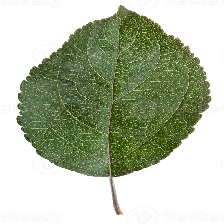

In [107]:
import csv
import time
from datetime import datetime, timezone

from IPython.display import display

demo_url = "https://static.vecteezy.com/system/resources/previews/011/855/781/non_2x/green-leaf-of-apple-tree-photo.jpg"
demo_path = WORK / "test.jpg"
!curl -sL {demo_url} --output {demo_path}

image = load_img(str(demo_path), target_size=IMAGE_TARGET_SIZE)
batch = np.expand_dims(img_to_array(image), 0).astype(np.float32)
logits = model.predict(batch, verbose=0)
probs = tf.nn.softmax(logits).numpy()[0]
idx = int(np.argmax(probs))
pred_class = CLASS_NAMES[idx]
conf = float(probs[idx])

print(f"Predicción: {pred_class} | Confianza: {conf:.2%} | Umbral val: {umbral_confianza:.2%}")
if conf < umbral_confianza:
    print("AVISO: baja confianza — resultado poco fiable.")

display(image)


## 11. Mapa de calor Grad-CAM (clase predicha)


In [108]:
tracker = EmissionsTracker(save_to_file=False, log_level="ERROR")
tracker.start()
start = time.perf_counter()

def last_convolution(m):
    conv_layers = []
    def walk(current):
        for layer in current.layers:
            if isinstance(layer, tf.keras.Model):
                walk(layer)
            elif len(layer.output.shape) == 4:
                conv_layers.append(layer)
    walk(m)
    return conv_layers[-1]

layer = last_convolution(model)
activations = {}
original_call = layer.call

def capture(*args, **kwargs):
    output = original_call(*args, **kwargs)
    activations["feature_map"] = output
    return output

layer.call = capture
try:
    with tf.GradientTape() as tape:
        predictions = model(batch, training=False)
        probabilities = tf.nn.softmax(tf.cast(predictions, "float32"))[0]
        index = int(tf.argmax(probabilities))
        score = tf.cast(predictions[0, index], "float32")
        feature_map = activations["feature_map"]
finally:
    layer.call = original_call

gradients = tape.gradient(score, feature_map)
weights = tf.reduce_mean(tf.cast(gradients, "float32"), axis=(1, 2))
cam = tf.reduce_sum(tf.cast(feature_map, "float32") * weights[:, None, None, :], axis=-1)
cam = tf.nn.relu(cam)[0]
cam = cam / (tf.reduce_max(cam) + 1e-8)
heatmap = tf.image.resize(cam[..., None], IMAGE_TARGET_SIZE)[..., 0].numpy()

predicted_class = CLASS_NAMES[index]
confidence = float(probabilities[index].numpy())

latency_s = time.perf_counter() - start
emisiones_kg = tracker.stop() or 0.0
energia_kwh = getattr(getattr(tracker, "_total_energy", None), "kWh", None)

header = ["timestamp", "image", "model", "class", "confidence", "latency_s", "energy_kwh", "emissions_kg"]
record = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "image": str(demo_path),
    "model": model.name,
    "class": predicted_class,
    "confidence": confidence,
    "latency_s": latency_s,
    "energy_kwh": energia_kwh,
    "emissions_kg": emisiones_kg,
}
file_path = WORK / "results" / "inference_cost.csv"
file_path.parent.mkdir(parents=True, exist_ok=True)
existed = file_path.exists()
with file_path.open("a", newline="") as fh:
    writer = csv.DictWriter(fh, fieldnames=header)
    if not existed:
        writer.writeheader()
    writer.writerow(record)

print(f"{predicted_class}: {confidence:.2%}")
print(f"Latencia: {latency_s:.3f} s | Energía: {energia_kwh} kWh | Emisiones: {emisiones_kg:.9f} kg CO2eq")
print("Registro guardado en:", file_path)

fig, (ax_original, ax_heatmap) = plt.subplots(1, 2, figsize=(10, 5))
ax_original.imshow(image)
ax_original.set_title("Original")
ax_heatmap.imshow(image)
ax_heatmap.imshow(heatmap, cmap="jet", alpha=0.5)
ax_heatmap.set_title(f"{predicted_class} ({confidence:.2%})")
for ax in (ax_original, ax_heatmap):
    ax.axis("off")
plt.tight_layout()
plt.show()


[codecarbon WARNING @ 00:29:51] Multiple instances of codecarbon are allowed to run at the same time.
/tmp/ipykernel_778/1792249652.py:1: FutureWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  tracker = EmissionsTracker(save_to_file=False, log_level="ERROR")


Apple___healthy: 75.44%
Latencia: 0.478 s | Energía: 8.233398245724652e-06 kWh | Emisiones: 0.000002088 kg CO2eq
Registro guardado en: /content/leafthealthvision/results/inference_cost.csv


## 7. Entrenamiento con class_weight (train) y early stopping

El test **no** se usa para ajustar hiperparámetros ni para definir el umbral de confianza. Se registran parámetros, métricas por época y huella de carbono en MLflow.


In [110]:
from datetime import datetime, timezone


/tmp/ipykernel_778/4170057192.py:11: FutureWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  tracker = EmissionsTracker(save_to_file=True, output_dir=str(RUN_DIR / "results"), output_file="emissions")
[codecarbon INFO @ 00:31:42] Emissions data (if any) will be saved to file /content/leafthealthvision/experiments/mobilenetv2/frozen/seed_42/results/emissions
[codecarbon INFO @ 00:31:42] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 00:31:42] >>> Tracker's metadata:
[codecarbon INFO @ 00:31:42]   Platform system: Linux-6.6.159+-x86_64-with-glibc2.39
[codecarbon INFO @ 00:31:42]   Python version: 3.13.16
[codecarbon INFO @ 00:31:42]   CodeCarbon version: 3.3.3
[codecarbon INFO @ 00:31:42]   Available RAM : 50.990 GB
[codecarbon INFO @ 00:31:42]   CPU count: 8 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 00:31:42]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecar

Epoch 1/10
38/68 ━━━━━━━━━━━━━━━━━━━━ 10s 349ms/step - accuracy: 0.9707 - loss: 0.1163

[codecarbon INFO @ 00:31:57] Energy consumed for RAM : 0.000083 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:31:57] Energy consumed for all GPUs : 0.000238 kWh. Total GPU Power : 57.05457150031532 W
[codecarbon INFO @ 00:31:57] Delta energy consumed for CPU with cpu_load : 0.000051 kWh, power : 12.124133525027537 W
[codecarbon INFO @ 00:31:57] Energy consumed for All CPU : 0.000051 kWh
[codecarbon INFO @ 00:31:57] 0.000372 kWh of electricity and 0.000000 L of water were used since the beginning.


68/68 ━━━━━━━━━━━━━━━━━━━━ 28s 393ms/step - accuracy: 0.9711 - loss: 0.1175 - val_accuracy: 0.9547 - val_loss: 0.1533
Epoch 2/10
 1/68 ━━━━━━━━━━━━━━━━━━━━ 1:50 2s/step - accuracy: 0.9703 - loss: 0.1175

[codecarbon INFO @ 00:32:12] Energy consumed for RAM : 0.000167 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:32:12] Energy consumed for all GPUs : 0.000477 kWh. Total GPU Power : 57.40975955097316 W
[codecarbon INFO @ 00:32:12] Delta energy consumed for CPU with cpu_load : 0.000028 kWh, power : 6.617133860527037 W
[codecarbon INFO @ 00:32:12] Energy consumed for All CPU : 0.000078 kWh
[codecarbon INFO @ 00:32:12] 0.000721 kWh of electricity and 0.000000 L of water were used since the beginning.


46/68 ━━━━━━━━━━━━━━━━━━━━ 7s 333ms/step - accuracy: 0.9730 - loss: 0.1084

... (28 outputs left out)

[codecarbon INFO @ 00:35:57] Energy consumed for RAM : 0.001416 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:35:57] Energy consumed for all GPUs : 0.004172 kWh. Total GPU Power : 59.12767969126083 W
[codecarbon INFO @ 00:35:57] Delta energy consumed for CPU with cpu_load : 0.000047 kWh, power : 11.180003441700357 W
[codecarbon INFO @ 00:35:57] Energy consumed for All CPU : 0.000660 kWh
[codecarbon INFO @ 00:35:57] 0.006248 kWh of electricity and 0.000000 L of water were used since the beginning.


68/68 ━━━━━━━━━━━━━━━━━━━━ 27s 370ms/step - accuracy: 0.9833 - loss: 0.0719 - val_accuracy: 0.9600 - val_loss: 0.1233


[codecarbon INFO @ 00:36:08] Energy consumed for RAM : 0.001476 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 00:36:08] Energy consumed for all GPUs : 0.004354 kWh. Total GPU Power : 60.009273708165985 W
[codecarbon INFO @ 00:36:08] Delta energy consumed for CPU with cpu_load : 0.000015 kWh, power : 5.002483949042997 W
[codecarbon INFO @ 00:36:08] Energy consumed for All CPU : 0.000675 kWh
[codecarbon INFO @ 00:36:08] 0.006505 kWh of electricity and 0.000000 L of water were used since the beginning.


Entrenamiento completo. Huella de carbono: 0.001649 kg CO2eq


In [ ]:
import mlflow


[codecarbon WARNING @ 00:21:44] Tracker already stopped or never started.


Finalizando run activo de MLflow: 69c54e26e47a4750b5c7ffd9317825ba
Tracker de CodeCarbon detenido con éxito.
